# Ariketa 4.3 — Gradientearen jaitsiera zerotik 🏔️ (EGITEKO)

Lehen bi ariketetan `LinearRegression()`-ek `w` eta `b` aurkitu ditu gure ordez.

Gaur galdera hau egingo dugu:

> **Nola ikasten ditu modeloak `w` eta `b`?**

Motorra guk geuk kodetuko dugu:

```text
1. IRAGARRI
      ↓
2. GALERA NEURTU (MSE)
      ↓
3. GRADIENTEA KALKULATU
      ↓
4. PARAMETROAK EGUNERATU
      ↓
5. ERREPIKATU
```

Hau Deep Learning-erako zubirik garrantzitsuenetako bat da.

### Nola lan egin

- 🟢 **KOMENTATU:** azaldu zure hitzekin.
- 🟡 **HUTSUNEAK BETE:** `____` osatu.
- 🔴 **KODETU ZEROTIK:** zati labur bat zuk idatzi.

> Gaur erabiliko dugun Gradient Descent mota **Batch Gradient Descent** da: epoch bakoitzean TRAIN lagin guztiak erabiltzen ditugu gradientea kalkulatzeko.


# 3.1 — Dataset bera, zuzen bera 🔁

Exercise 1-eko problema bera erabiliko dugu:

```text
x = weight (lb)
y = mpg
```

Helburua:

> **Exercise 1-en scikit-learn-ek aurkitu zuen zuzen bera orain Gradient Descent bidez aurkitzea.**

Lehenengo, `weight` eta `mpg` bakarrik aukeratu eta gero kenduko ditugu haietan dauden balio faltak.

### Zergatik eskalatu `x`?

Pisua milaka libratan dago. Eskalatu gabe, `w`-ren gradientea `b`-rena baino askoz eskala handiagoan egon daiteke eta learning rate bera erabiltzea zailagoa da.

Beraz:

```text
x_scaled = (x - TRAIN mean) / TRAIN std
```

Ez dugu `y` eskalatuko: mpg unitateetan mantenduko dugu galera ulergarriagoa izateko.


In [1]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


# ============================================================
# DATASET-A
# ============================================================

df_raw = sns.load_dataset("mpg")

df = df_raw[[
    "weight",
    "mpg"
]].copy()

df = df.dropna()


X = df["weight"].to_numpy(
    dtype=float
)

y = df["mpg"].to_numpy(
    dtype=float
)


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


# ============================================================
# SCALING — TRAIN ESTATISTIKOAK BAKARRIK
# ============================================================

mu = X_train.mean()
sd = X_train.std()

x_train = (
    X_train - mu
) / sd

x_test = (
    X_test - mu
) / sd


print(
    "TRAIN:",
    len(x_train)
)

print(
    "TEST:",
    len(x_test)
)

print(
    "x_train mean:",
    round(
        x_train.mean(),
        3
    )
)

print(
    "x_train std:",
    round(
        x_train.std(),
        3
    )
)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# 1. Zergatik kalkulatzen ditugu mu eta sd TRAIN-ekin bakarrik?
#
# ERANTZUNA:
#Datu-ihesa (Data Leakage) saihesteko. Test-multzoak ereduak inoiz ikusi ez dituen
# "etorkizuneko datu ezezagunak" simulatu behar ditu. Test datuen informazioa (mu edo sd)
# erabiliko bagenu, ereduak entrenatzean erabili beharko ez lukeen informazioa jasoko luke.
#
#
# 2. Zergatik eskalatzen dugu x, baina y mpg-tan uzten dugu?
#
# ERANTZUNA:
#Iragarpenak eta akats-metrikak (MAE, RMSE) jatorrizko eta benetako unitateetan (mpg)
# zuzenean interpretatu ahal izateko. Feature-ak (x) eskalatzeak algoritmoaren ikaskuntza
# hobetzen du, baina helburu-aldagaia (y) ez da eskalatu behar berezko unitateetan neurtu nahi bada.
#
#


TRAIN: 318
TEST: 80
x_train mean: 0.0
x_train std: 1.0


# 3.2 — Zer optimizatu nahi dugu? 🎯

Gure modeloa:

$$
\hat{y} = wx+b
$$

Eta galera:

$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

`w` eta `b` aldatu ahala, MSE ere aldatzen da.

Helburua:

> **MSE minimo egiten duten `w` eta `b` aurkitzea.**

Linear Regression + MSE kasuan loss surface-a **ganbila** da: bowl moduko gainazala, minimo global bakarrarekin.

⚠️ Horrek ez du esan nahi edozein learning rate-k funtzionatuko duenik. Urratsa handiegia bada, minimotik jauzi egin eta dibergitu gaitezke.


In [2]:
# ============================================================
# BI FUNTZIO NAGUSI
# ============================================================

def iragarri(
    w,
    b,
    x
):
    return (
        w * x
        + b
    )


def mse(
    w,
    b,
    x,
    y_true
):
    y_pred = iragarri(
        w,
        b,
        x
    )

    return np.mean(
        (
            y_true
            - y_pred
        ) ** 2
    )


print(
    "Hasierako MSE (w=0, b=0):",
    round(
        mse(
            0,
            0,
            x_train,
            y_train
        ),
        2
    )
)


Hasierako MSE (w=0, b=0): 620.04


# 3.3 — MSE-ren “harana” ikusi 🏔️

Lehenengo, `b` balio bat finkatuko dugu eta `w` bakarrik aldatuko dugu.

Horrela MSE-ren sekzio bat ikusiko dugu:

```text
MSE
 ^
 |       \       /
 |        \_____/
 +----------------> w
          minimoa
```

Parabola honek intuizio hau ematen digu:

> **malda (gradient) positiboa bada, kontrako norabidean joan behar dugu; negatiboa bada, beste aldera.**


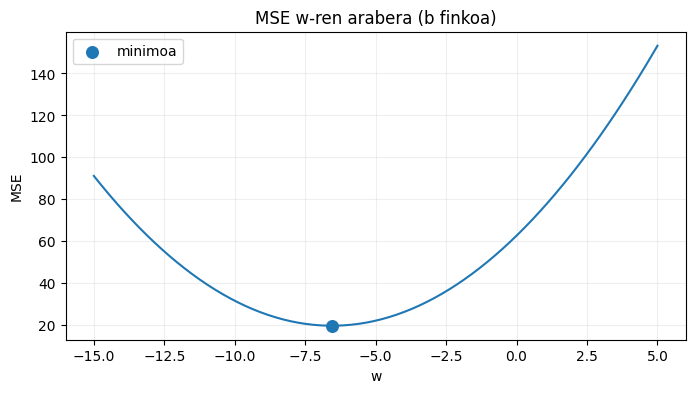

In [3]:
b_fix = y_train.mean()

ws = np.linspace(
    -15,
    5,
    150
)

mse_ws = [
    mse(
        w_value,
        b_fix,
        x_train,
        y_train
    )
    for w_value in ws
]


plt.figure(
    figsize=(8, 4)
)

plt.plot(
    ws,
    mse_ws
)

min_idx = int(
    np.argmin(
        mse_ws
    )
)

plt.scatter(
    [
        ws[min_idx]
    ],
    [
        mse_ws[min_idx]
    ],
    s=70,
    label="minimoa"
)

plt.xlabel(
    "w"
)

plt.ylabel(
    "MSE"
)

plt.title(
    "MSE w-ren arabera (b finkoa)"
)

plt.legend()
plt.grid(
    alpha=0.2
)

plt.show()


# 3.4 — Gradientea: zein norabidetan mugitu? 🧭

MSE-ren gradienteak esaten digu galerak nola aldatzen diren `w` eta `b` aldatzean.

$$
\frac{\partial MSE}{\partial w}
=
\frac{2}{n}
\sum_{i=1}^{n}
(\hat{y}_i-y_i)x_i
$$

$$
\frac{\partial MSE}{\partial b}
=
\frac{2}{n}
\sum_{i=1}^{n}
(\hat{y}_i-y_i)
$$

Eta Gradient Descent-en eguneratzea:

$$
w_{new}
=
w_{old}
-
\eta
\frac{\partial MSE}{\partial w}
$$

$$
b_{new}
=
b_{old}
-
\eta
\frac{\partial MSE}{\partial b}
$$

non:

```text
η = learning rate
```

### 🟢 Interpretatu

Zergatik kentzen dugu gradientea (`- η · gradient`) eta ez gehitu?

**ERANTZUNA:**
Gradienteak galera (MSE) **gehien igotzen den** norabidea adierazten duelako. Guk MSE txikitu nahi dugunez, kontrako norabidean mugitu behar dugu. Adibidez, `dw > 0` bada, `w` handitzean MSE handitzen da → `w` txikitu behar dugu (`w - η·dw`). `dw < 0` bada, alderantziz: `w` handitu. Gradientea gehituko bagenu, haranean gora joango ginateke (Gradient **Ascent**) eta errorea handituko litzateke.


# 3.5 — Lehen epoch-a lupa batekin 🔬

Begizta osoa egin aurretik, **lehen urratsa** bakarrik ikusiko dugu.

Hasiera:

```text
w = 0
b = 0
```

Beraz hasieran:

```text
ŷ = 0
```

TRAIN lagin guztientzat.

Ondoren:

```text
predictions
   ↓
errors = ŷ - y
   ↓
dw, db
   ↓
w_new, b_new
   ↓
MSE berria
```

Hau da Gradient Descent begiztaren bihotza.


In [5]:
w0 = 0.0
b0 = 0.0
lr = 0.10

p0 = iragarri(
    w0,
    b0,
    x_train
)

errorea0 = (
    p0
    - y_train
)

n = len(
    x_train
)


# ============================================================
# 🟡 HUTSUNEAK BETE
# ============================================================

dw0 = (2 / n) * np.sum(
    errorea0 * x_train
)

db0 = (2 / n) * np.sum(
    errorea0
)


w1 = (
    w0
    - lr * dw0
)

b1 = (
    b0
    - lr * db0
)


print(
    "w0, b0:",
    w0,
    b0
)

print(
    "dw0, db0:",
    round(dw0, 3),
    round(db0, 3)
)

print(
    "w1, b1:",
    round(w1, 3),
    round(b1, 3)
)

print(
    "MSE hasieran:",
    round(
        mse(
            w0,
            b0,
            x_train,
            y_train
        ),
        2
    )
)

print(
    "MSE urrats 1 ondoren:",
    round(
        mse(
            w1,
            b1,
            x_train,
            y_train
        ),
        2
    )
)


# Lehen 5 iragarpenak ere ikusi
lehen_5 = pd.DataFrame({
    "x_scaled": x_train[:5],
    "y_true": y_train[:5],
    "y_pred_epoch0": p0[:5],
    "error_epoch0": errorea0[:5]
})

display(
    lehen_5.round(3)
)

w0, b0: 0.0 0.0
dw0, db0: 13.102 -47.216
w1, b1: -1.31 4.722
MSE hasieran: 620.04
MSE urrats 1 ondoren: 403.95


,x_scaled,y_true,y_pred_epoch0,error_epoch0
0,0.553,16.0,0.0,-16.0
1,-1.000,27.0,0.0,-27.0
2,-1.125,37.0,0.0,-37.0
3,-1.393,36.1,0.0,-36.1
4,-0.328,23.0,0.0,-23.0


# 3.6 — Orain bai: entrenamendu-begizta osoa 🔁

Epoch bakoitzean:

```text
1. forward / iragarri
2. MSE neurtu
3. residualak kalkulatu
4. dw eta db kalkulatu
5. w eta b eguneratu
```

`w_hist` eta `b_hist` ere gordeko ditugu gero ikasketa-bidea marrazteko.


In [9]:
w = 0.0
b = 0.0

lr = 0.10
epochs = 50

n = len(
    x_train
)

historia = []
w_hist = []
b_hist = []


for epoch in range(
    epochs
):

    # Egoera gorde
    w_hist.append(
        w
    )

    b_hist.append(
        b
    )

    # 1) IRAGARRI
    p = iragarri(
        w,
        b,
        x_train
    )

    # 2) GALERA GORDE
    historia.append(
        np.mean(
            (
                y_train - p
            ) ** 2
        )
    )

    # 3) ERROREA
    errorea = (
        p
        - y_train
    )

    # ========================================================
    # 🟡 HUTSUNEAK: GRADIENTEAK
    # ========================================================

    dw = (2 / n) * np.sum(
        errorea * x_train
    )

    db = (2 / n) * np.sum(
        errorea
    )

    # ========================================================
    # 🟡 HUTSUNEAK: EGUNERATU GRADIENTEAREN KONTRA
    # ========================================================

    w = (
        w
        - lr * dw
    )

    b = (
        b
        - lr * db
    )


# Azken egoera ere gorde
w_hist.append(
    w
)

b_hist.append(
    b
)

historia.append(
    mse(
        w,
        b,
        x_train,
        y_train
    )
)


print(
    "Amaierako w:",
    round(
        w,
        5
    )
)

print(
    "Amaierako b:",
    round(
        b,
        5
    )
)

print(
    "Hasierako MSE:",
    round(
        historia[0],
        2
    )
)

print(
    "Amaierako MSE:",
    round(
        historia[-1],
        2
    )
)

Amaierako w: -6.55081
Amaierako b: 23.60784
Hasierako MSE: 620.04
Amaierako MSE: 19.78


# 3.7 — Galera-kurba: “ikastea” ikusi 📉

Modeloa ikasten ari bada:

```text
MSE
↓
↓
↓
minimoaren ingurura
```

Epoch gehiago egiteak ez du zertan hobekuntza infinitua ekarri: minimoaren inguruan egonkortzen da.


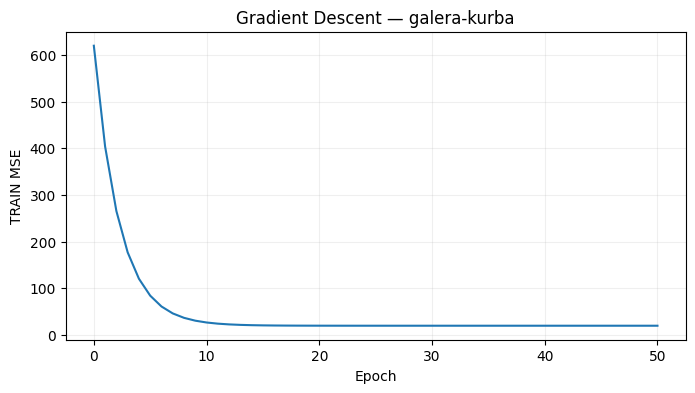

In [10]:
plt.figure(
    figsize=(8, 4)
)

plt.plot(
    range(
        len(historia)
    ),
    historia
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "TRAIN MSE"
)

plt.title(
    "Gradient Descent — galera-kurba"
)

plt.grid(
    alpha=0.2
)

plt.show()


# 3.8 — Zuzenak nola ikasten duen ikusi 🎬

Orain parametroak hainbat epoch-etan hartuko ditugu eta zuzenak nola mugitzen diren ikusiko dugu.

Hau da ikasketa geometrikoki:

```text
zuzen txarra
   ↓
zuzen hobea
   ↓
zuzen hobea
   ↓
MSE minimoaren inguruko zuzena
```


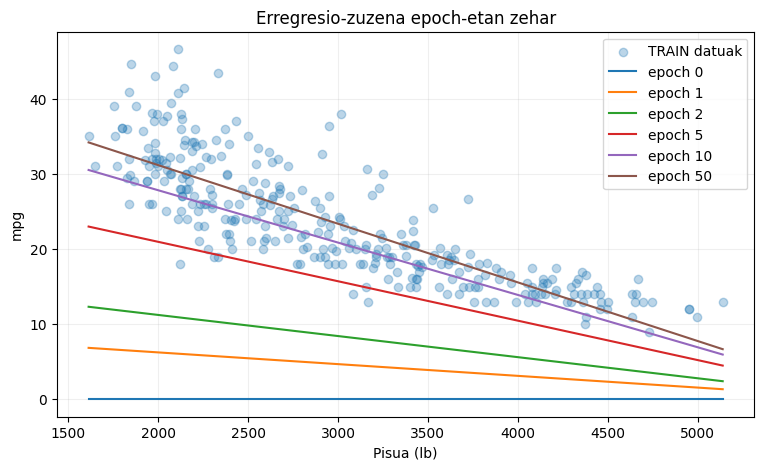

In [11]:
plt.figure(
    figsize=(9, 5)
)

plt.scatter(
    X_train,
    y_train,
    alpha=0.30,
    label="TRAIN datuak"
)


x_raw_line = np.linspace(
    X_train.min(),
    X_train.max(),
    200
)

x_scaled_line = (
    x_raw_line - mu
) / sd


epoch_aukeratuak = [
    0,
    1,
    2,
    5,
    10,
    50
]


for e in epoch_aukeratuak:

    w_e = w_hist[e]
    b_e = b_hist[e]

    y_line = iragarri(
        w_e,
        b_e,
        x_scaled_line
    )

    plt.plot(
        x_raw_line,
        y_line,
        label=f"epoch {e}"
    )


plt.xlabel(
    "Pisua (lb)"
)

plt.ylabel(
    "mpg"
)

plt.title(
    "Erregresio-zuzena epoch-etan zehar"
)

plt.legend()
plt.grid(
    alpha=0.2
)

plt.show()


# 3.9 — Gradient Descent-en bidea MSE gainazalean 🗺️

Orain Aizkorri analogia matematikan ikusiko dugu.

Ardatzak:

```text
x-axis → w
y-axis → b
contour-ak → MSE mailak
```

Puntuak:

```text
(w0,b0)
→ (w1,b1)
→ (w2,b2)
→ ...
→ minimoa
```

Hau da “haranean behera” joatea.


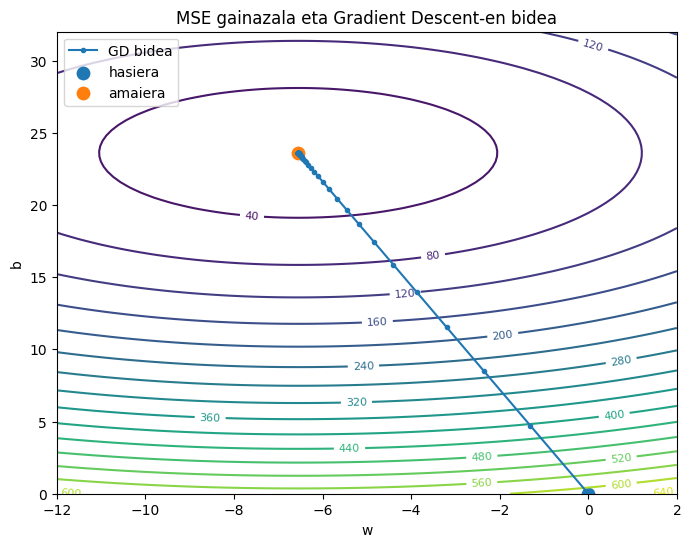

In [12]:
# Grid bat sortu w eta b-ren inguruan
w_values = np.linspace(
    -12,
    2,
    90
)

b_values = np.linspace(
    0,
    32,
    90
)

W, B = np.meshgrid(
    w_values,
    b_values
)

Z = np.empty_like(
    W
)


for i in range(
    W.shape[0]
):
    for j in range(
        W.shape[1]
    ):
        Z[i, j] = mse(
            W[i, j],
            B[i, j],
            x_train,
            y_train
        )


plt.figure(
    figsize=(8, 6)
)

contours = plt.contour(
    W,
    B,
    Z,
    levels=18
)

plt.clabel(
    contours,
    inline=True,
    fontsize=8
)

plt.plot(
    w_hist,
    b_hist,
    marker="o",
    markersize=3,
    label="GD bidea"
)

plt.scatter(
    [w_hist[0]],
    [b_hist[0]],
    s=80,
    label="hasiera"
)

plt.scatter(
    [w_hist[-1]],
    [b_hist[-1]],
    s=80,
    label="amaiera"
)

plt.xlabel(
    "w"
)

plt.ylabel(
    "b"
)

plt.title(
    "MSE gainazala eta Gradient Descent-en bidea"
)

plt.legend()
plt.show()


# 3.10 — sklearn-ekin konparatu ✅

`LinearRegression()` eta gure Gradient Descent-ek helburu bera dute:

> **TRAIN datuen squared error minimizatzea.**

Baina ez dute algoritmo bera erabiltzen:

- gure kodea → **iterative Gradient Descent**
- `sklearn.LinearRegression` → **Ordinary Least Squares solver**

Linear Regression + MSE problema ganbila denez, bi metodoek minimo bera edo ia bera aurkitu beharko lukete.


In [13]:
sk_model_scaled = LinearRegression()

sk_model_scaled.fit(
    x_train.reshape(
        -1,
        1
    ),
    y_train
)


print(
    "GD eskuz:"
)

print(
    "  w =",
    round(
        w,
        6
    )
)

print(
    "  b =",
    round(
        b,
        6
    )
)


print(
    "\nsklearn:"
)

print(
    "  w =",
    round(
        sk_model_scaled.coef_[0],
        6
    )
)

print(
    "  b =",
    round(
        sk_model_scaled.intercept_,
        6
    )
)


print(
    "\nDiferentziak:"
)

print(
    "  |Δw| =",
    abs(
        w
        - sk_model_scaled.coef_[0]
    )
)

print(
    "  |Δb| =",
    abs(
        b
        - sk_model_scaled.intercept_
    )
)


gd_test_pred = iragarri(
    w,
    b,
    x_test
)


print(
    "\nTEST R²:",
    round(
        r2_score(
            y_test,
            gd_test_pred
        ),
        3
    )
)


GD eskuz:
  w = -6.550807
  b = 23.607839

sklearn:
  w = -6.550901
  b = 23.608176

Diferentziak:
  |Δw| = 9.349757749266274e-05
  |Δb| = 0.0003369471486855957

TEST R²: 0.723


# 3.11 — Itzuli unitate errealetara 🔄

Gradient Descent-en `w` balioa scaled `x`-rako da.

Gogoratu:

$$
x'=\frac{x-\mu}{\sigma}
$$

Eta:

$$
\hat{y}=w'x'+b'
$$

Unitate originaletara itzuliz:

$$
w_{raw}=\frac{w'}{\sigma}
$$

$$
b_{raw}=b'-\frac{w'\mu}{\sigma}
$$

Orain ez dugu Exercise 1-eko zenbakirik hard-code egingo.

Zuzenena da **raw TRAIN datuekin sklearn modeloa berriro entrenatzea** eta bi zuzenak konparatzea.


In [15]:
# ============================================================
# 🔴 KODETU ZEROTIK
# ============================================================
#
# 1. Kalkulatu w_raw = w / sd
# 2. Kalkulatu b_raw = b - w * mu / sd
# 3. Entrenatu LinearRegression raw X_train erabiliz
# 4. Konparatu koefizienteak


# IDATZI HEMEN:
# 1 & 2. Eskuz ikasitako parametroak jatorrizko eskalara pasatu
w_raw = w / sd
b_raw = b - (w * mu / sd)

# 3. LinearRegression entrenatu jatorrizko (raw) X_train erabiliz
eredua_raw = LinearRegression()
eredua_raw.fit(X_train.reshape(-1, 1), y_train)

w_sklearn = eredua_raw.coef_[0]
b_sklearn = eredua_raw.intercept_

# 4. Koefizienteak konparatu
print("--- Eskuz des-eskalatutako parametroak ---")
print("w_raw:", round(w_raw, 6))
print("b_raw:", round(b_raw, 4))

print("\n--- scikit-learn (raw) parametroak ---")
print("w_sklearn:", round(w_sklearn, 6))
print("b_sklearn:", round(b_sklearn, 4))

print("\nKonparazioa:")
print("w berdinak dira?:", np.isclose(w_raw, w_sklearn, atol=1e-3))
print("b berdinak dira?:", np.isclose(b_raw, b_sklearn, atol=1e-3))


--- Eskuz des-eskalatutako parametroak ---
w_raw: -0.007805
b_raw: 46.7814

--- scikit-learn (raw) parametroak ---
w_sklearn: -0.007805
b_sklearn: 46.7821

Konparazioa:
w berdinak dira?: True
b berdinak dira?: True


# 3.12 — BONUS: learning rate-k zer egiten du? 🚦

Loss surface-a ganbila izateak ez du esan nahi edozein `lr` erabil dezakegunik.

Konparatuko ditugu:

```text
lr = 0.01  → motela
lr = 0.10  → egokia
lr = 1.10  → handiegia, dibergitzeko arriskua
```

Helburua ez da “lr onena” bilatzea, baizik eta **urratsaren tamainaren efektua ikustea**.


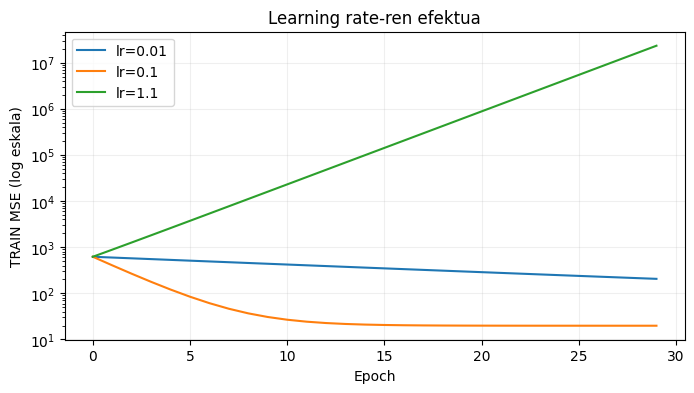

In [14]:
def entrenatu_gd(
    lr_value,
    epochs_value=30
):
    w_tmp = 0.0
    b_tmp = 0.0
    historia_tmp = []

    n_tmp = len(
        x_train
    )

    for _ in range(
        epochs_value
    ):
        p_tmp = iragarri(
            w_tmp,
            b_tmp,
            x_train
        )

        historia_tmp.append(
            np.mean(
                (
                    y_train - p_tmp
                ) ** 2
            )
        )

        error_tmp = (
            p_tmp
            - y_train
        )

        dw_tmp = (
            2 / n_tmp
        ) * np.sum(
            error_tmp
            * x_train
        )

        db_tmp = (
            2 / n_tmp
        ) * np.sum(
            error_tmp
        )

        w_tmp = (
            w_tmp
            - lr_value * dw_tmp
        )

        b_tmp = (
            b_tmp
            - lr_value * db_tmp
        )

    return historia_tmp


plt.figure(
    figsize=(8, 4)
)

for lr_value in [
    0.01,
    0.10,
    1.10
]:
    h = entrenatu_gd(
        lr_value
    )

    plt.plot(
        h,
        label=f"lr={lr_value}"
    )


plt.yscale(
    "log"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "TRAIN MSE (log eskala)"
)

plt.title(
    "Learning rate-ren efektua"
)

plt.legend()
plt.grid(
    alpha=0.2
)

plt.show()


### 🟢 Hausnarketa

1. Zer gertatzen da `lr` txikiegia denean?

**ERANTZUNA:**
Konbergentzia oso motela da. Urratsak txikiegiak direnez, ereduak epoch gehiegi behar ditu gutxieneko globalera iristeko, eta iteration muga gaindituz gero, optimizazioa amaitu gabe gelditu daiteke.

2. Zer gertatzen da `lr` handiegia denean?

**ERANTZUNA:**
Algoritmoak gutxieneko globala gainditzen du (overshooting) eta dibergitu egiten du. Urrats bakoitzean kontrako aldera jauzi handiegia eginez, errorea (MSE) txikitu beharrean etengabe hazten da (NaN edo Inf balioetara iritsi arte).

3. Loss surface-a ganbila bada ere, zergatik dibergitu dezakegu?

**ERANTZUNA:**
Gainazala ganbila izateak gutxieneko global bakarra dagoela bermatzen du (ez dagoela tokiko gutxieneko tranparik), baina ez du bermatzen bidean erortzen garenik. Dibergentzia optimizazio-urratsaren tamainaren (lr) mende dago: malda jarraituz urrats luzegia egiten badugu, gutxienekotik haratago pasatu eta errore handiagoko eremu batera iritsiko gara.


# 3.13 — Deep Learning-erako zubia 🧠➡️🧠🧠🧠

Gaur egin duguna:

```text
INPUT x
   ↓
FORWARD
ŷ = wx+b
   ↓
LOSS
MSE
   ↓
GRADIENTEAK
dw, db
   ↓
UPDATE
w, b aldatu
```

### Garrantzizko ñabardura

Gaur `dw` eta `db` formulak zuzenean kalkulatu ditugu.

Sare neuronal batean milioika parametro egon daitezke. **Backpropagation** algoritmoak chain rule erabiliz parametro guztien gradienteak modu eraginkorrean kalkulatzen ditu.

Beraz:

> Gaurko ariketa **backpropagation-en oinarrizko ideia/motor bera** da, baina neurona lineal bakar batean gradienteak zuzenean kalkulatu ditugu.

### 🟢 Osatu

- `w`, `b` = modeloko parametroak
- `ŷ = wx+b` = forwardpass / aurrera-pasa
- MSE = loss function
- `dw`, `db` = galeraren **gradienteak** (deribatu partzialak)
- `w := w - lr·dw` = optimizer-aren **eguneratze-urratsa** (update rule)
- epoch honetan TRAIN osoa erabiltzea = **Batch** Gradient Descent


# Ondorioak ✅

Ariketa honetan modelo baten “ikasketa” barrutik ikusi dugu.

```text
w,b hasieratu
    ↓
ŷ kalkulatu
    ↓
MSE kalkulatu
    ↓
dw,db kalkulatu
    ↓
w,b eguneratu
    ↓
errepikatu
```

Gako-ideiak:

1. **MSE** minimizatzen ari gara.
2. **Gradienteak** loss-a gehien igotzen den norabidea adierazten du.
3. **Gradient Descent** kontrako norabidean mugitzen da.
4. `x` eskalatzeak optimizazioa errazten du.
5. Linear Regression + MSE loss surface-a **ganbila** da: minimo global bakarra.
6. Hala ere, **learning rate handiegiak dibergentzia** eragin dezake.
7. Gure GD eta sklearn OLS-k **minimo bera** bilatzen dute, algoritmo desberdinez.
8. Scaled `w,b` berriro unitate originaletara itzul daitezke.
9. Gaurko `predict → loss → gradients → update` zikloa **Deep Learning-en entrenamenduaren oinarria** da.
10. Sare neuronaletan, **backpropagation-ek** parametro askoren gradienteak chain rule bidez kalkulatuko ditu.

> **Hemen ulertzen badugu motorra, Deep Learning-en ez dugu magia berri bat aurkituko: motor bera eskala handiagoan erabiliko dugu.**
